In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
url = "https://www.data.gouv.fr/api/1/datasets/r/1c3f80c4-ace5-41ef-b6e1-983a8ccb5c69"

# Lecture directe depuis l'URL (sans sauvegarde locale)
df = pd.read_csv(url, sep=",", encoding="utf-8", engine="python", on_bad_lines="warn")

print("Chargé depuis l'URL")
print("Dimensions:", df.shape)
df.head()

Chargé depuis l'URL
Dimensions: (17969, 24)


,Nom,Prénom,Sexe,Nom de naissance,Nom d'épouse,Précision sur l'individu,Type de brevet,Commune,Adresse(s) professionnelle(s),Date de naissance,...,Précision sur le brevet,Spécialité,Date de début du brevet,Date de fin du brevet,Motif de fin du brevet,Prédécesseur(s),Successeur(s),Commune actuelle,Département,Géolocalisation
0,BAUDET,Alexandre Vincent-de-Paul,homme,BAUDET,NaN,NaN,lithographe,Paris,"124, galerie Saint-Marc (passage des Panoramas)",1806-05-14,...,NaN,Écritures autographiques,4 décembre 1837,NaN,NaN,NaN,"Lamblot (Victor, Jules, Louis)",Paris,Seine,"48.856944444444, 2.3513888888889"
1,BEAUSSE,Jean François,homme,BEAUSSE,NaN,NaN,libraire,Paris,"23, rue Neuve-Guillemain,22, cour du Harlay",1787-03-17,...,NaN,NaN,20 décembre 1831,26 octobre 1857,NaN,NaN,"Caudrilier (Adolphe, Nicolas, François)",Paris,Seine,"48.856944444444, 2.3513888888889"
2,BEGAULT,Louise Alphonsine,femme,BEGAULT,TORBIER,NaN,libraire,Paris,"2, rue Saint-Ferdinand",1828-08-10,...,NaN,NaN,8 juillet 1870,NaN,NaN,NaN,NaN,Paris,Seine,"48.856944444444, 2.3513888888889"
3,BÉJOT,Édouard Paul,homme,BÉJOT,NaN,NaN,lithographe,Paris,"40, rue de Seine",1825-06-09,...,NaN,"Travaux commerciaux (factures, mandats)",7 juillet 1851,7 janvier 1856,NaN,"Gourdault (François, Alexandre)","Frick (Louis, Édouard)",Paris,Seine,"48.856944444444, 2.3513888888889"
4,BERGELOT,Jean Baptiste Émile,homme,BERGELOT,NaN,NaN,libraire,Paris,2 rue Neuve Bourg-l'Abbé,1828-02-18,...,NaN,NaN,3 avril 1855,18 mai 1863,décès,Rolin (Henri),"Cosnard (Jules, Louis)",Paris,Seine,"48.856944444444, 2.3513888888889"


# EVOLUTION TEMPORELLE

In [ ]:
# Construire le volume annuel de librairies "ouvertes" (1810-1881)
start_period, end_period = 1810, 1881

# 1) Garder les lignes qui concernent au moins "libraire"
lib = df[df["Type de brevet"].fillna("").str.contains(r"(^|,)libraire(,|$)", regex=True)].copy()

# 2) Extraire l'année de début/fin depuis les chaînes de dates
lib["start_year"] = pd.to_numeric(
    lib["Date de début du brevet"].astype(str).str.extract(r"(\d{4})", expand=False),
    errors="coerce"
)
lib["end_year"] = pd.to_numeric(
    lib["Date de fin du brevet"].astype(str).str.extract(r"(\d{4})", expand=False),
    errors="coerce"
)

# 3) Règles de période :
# - sans date de fin => on considère ouvert jusqu'à la fin de la fenêtre étudiée
# - on tronque les intervalles à [1810, 1881]
lib["start_year"] = lib["start_year"].clip(lower=start_period, upper=end_period)
lib["end_year"] = lib["end_year"].fillna(end_period).clip(lower=start_period, upper=end_period)

# 4) Conserver intervalles valides
lib = lib[lib["start_year"].notna() & (lib["start_year"] <= lib["end_year"])].copy()
lib[["start_year", "end_year"]] = lib[["start_year", "end_year"]].astype(int)

# 5) Compter le nombre de librairies ouvertes par année
years = np.arange(start_period, end_period + 1)
open_counts = pd.Series(0, index=years, dtype=int)

for s, e in zip(lib["start_year"], lib["end_year"]):
    open_counts.loc[s:e] += 1

timeline = pd.DataFrame({"annee": open_counts.index, "nb_librairies_ouvertes": open_counts.values})
print("Nb lignes libraire retenues:", len(lib))

/var/folders/r9/cjr0gj197xd220l1s09cyl_c0000gp/T/ipykernel_99485/3544982450.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  lib = df[df["Type de brevet"].fillna("").str.contains(r"(^|,)libraire(,|$)", regex=True)].copy()


Nb lignes libraire retenues: 3779
Timeline shape: (72, 2)


,annee,nb_librairies_ouvertes
0,1810,1
1,1811,53
2,1812,370
3,1813,406
4,1814,407


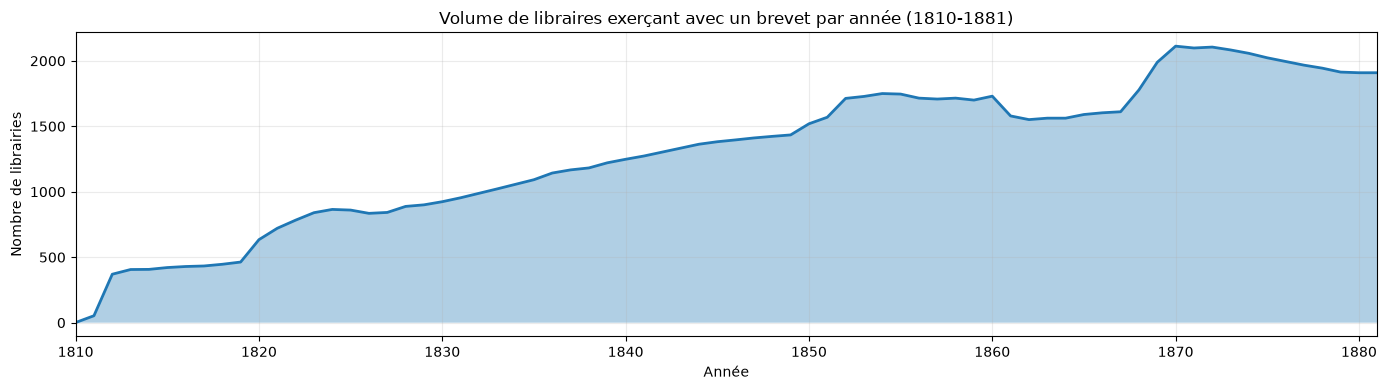

In [ ]:
plt.figure(figsize=(14, 4))
plt.fill_between(timeline["annee"], timeline["nb_librairies_ouvertes"], alpha=0.35)
plt.plot(timeline["annee"], timeline["nb_librairies_ouvertes"], linewidth=2)
plt.title("Volume de libraires exerçant avec un brevet par année (1810-1881)")
plt.xlabel("Année")
plt.ylabel("Nombre de librairies")
plt.xlim(1810, 1881)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [15]:
# Nombre de nouveaux brevets par année
ouvertures = (
    lib.groupby("start_year")
       .size()
       .rename("nouveaux_brevets")
)

# Nombre de brevets terminés par année
fermetures = (
    lib[lib["end_year"] < end_period]
    .groupby("end_year")
    .size()
    .rename("brevets_termines")
)

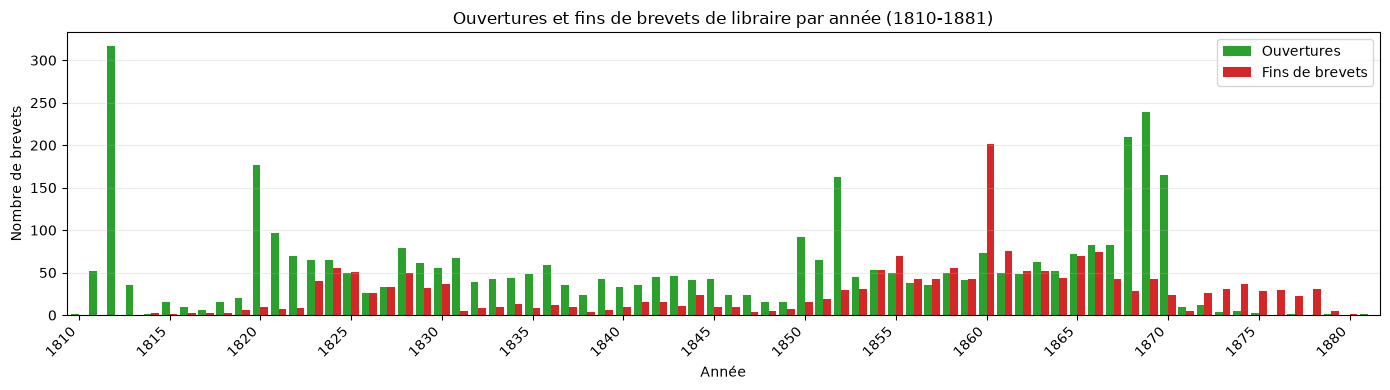

In [16]:
# Préparer les ouvertures et les fins de brevets pour toutes les années
mouvements = pd.DataFrame({
    "ouvertures": ouvertures.reindex(timeline["annee"], fill_value=0).to_numpy(),
    "fermetures": fermetures.reindex(timeline["annee"], fill_value=0).to_numpy(),
}, index=timeline["annee"])

ax = mouvements.plot(
    kind="bar", figsize=(14, 4), width=0.85,
    color=["#2ca02c", "#d62728"],
)
ax.set_title("Ouvertures et fins de brevets de libraire par année (1810-1881)")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de brevets")
ax.set_xticks(range(0, len(mouvements), 5))
ax.set_xticklabels(mouvements.index[::5], rotation=45, ha="right")
ax.legend(["Ouvertures", "Fins de brevets"])
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# Durée moyenne des brevets de libraire
np.mean(lib["end_year"] - lib["start_year"])

np.float64(23.72797036252977)

# PROFIL DES LIBRAIRES

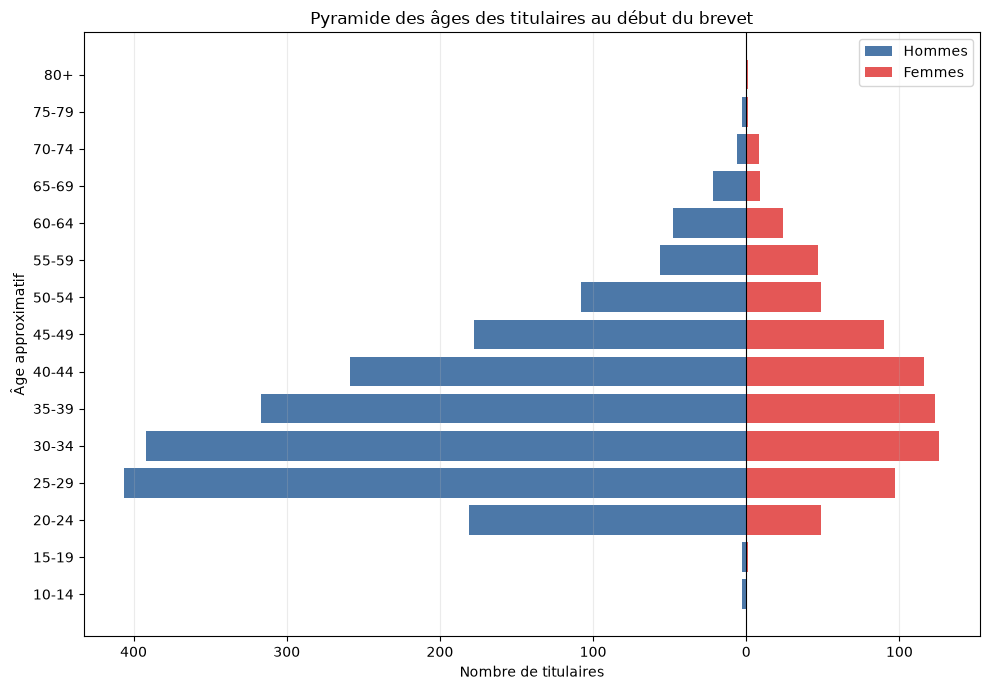

Titulaires représentés : 2726


In [ ]:
# Calculer l'âge approximatif au début du brevet
ages = df[["Sexe", "Date de naissance", "start_year"]].copy()
ages["birth_year"] = pd.to_numeric(
    ages["Date de naissance"].astype(str).str.extract(r"(\d{4})", expand=False),
    errors="coerce",
)
ages["age"] = ages["start_year"] - ages["birth_year"]
ages = ages.dropna(subset=["Sexe", "age"])
ages = ages[ages["age"].between(10, 100)].copy()

# Regrouper les âges par classes de cinq ans
bins = list(range(10, 81, 5)) + [float("inf")]
labels = [f"{age}-{age + 4}" for age in range(10, 80, 5)] + ["80+"]
ages["classe_age"] = pd.cut(ages["age"], bins=bins, labels=labels, right=False)
pyramide = pd.crosstab(ages["classe_age"], ages["Sexe"]).reindex(labels, fill_value=0)

hommes = -pyramide.get("homme", pd.Series(0, index=pyramide.index))
femmes = pyramide.get("femme", pd.Series(0, index=pyramide.index))

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(labels, hommes, color="#4c78a8", label="Hommes")
ax.barh(labels, femmes, color="#e45756", label="Femmes")
ax.set_title("Pyramide des âges des titulaires au début du brevet")
ax.set_xlabel("Nombre de titulaires")
ax.set_ylabel("Âge approximatif")
ax.xaxis.set_major_formatter(lambda valeur, position: f"{abs(int(valeur))}")
ax.axvline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Titulaires représentés : {len(ages)}")

Nombre de titulaires avec un prénom renseigné : 3757
Nombre de prénoms différents : 2546
Part de prénoms composés : 75.7%


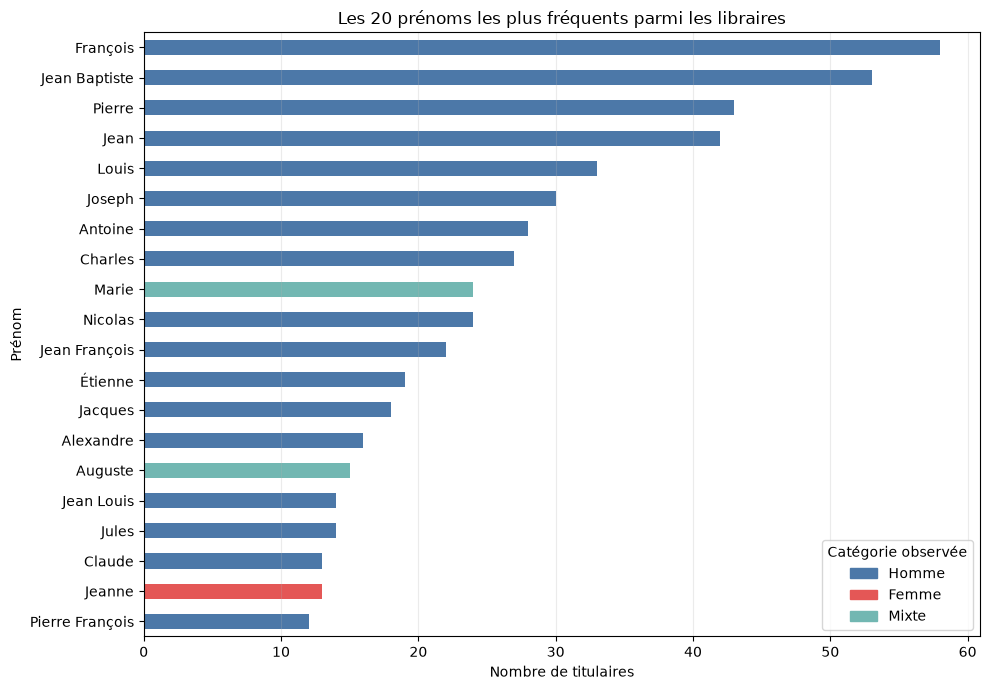

In [24]:
# Première analyse des prénoms
profil_prenoms = lib[["Prénom", "Sexe"]].dropna().copy()
profil_prenoms["Prénom"] = profil_prenoms["Prénom"].str.strip()
profil_prenoms = profil_prenoms[profil_prenoms["Prénom"].ne("")]
prenoms = profil_prenoms["Prénom"]

print(f"Nombre de titulaires avec un prénom renseigné : {len(prenoms)}")
print(f"Nombre de prénoms différents : {prenoms.nunique()}")
part_composes = prenoms.str.contains(r"\s", regex=True).mean()
print(f"Part de prénoms composés : {part_composes:.1%}")

sexes_par_prenom = profil_prenoms.groupby("Prénom")["Sexe"].agg(set)
top_prenoms = prenoms.value_counts().head(20).sort_values()
couleurs_sexe = {
    "homme": "#4c78a8",
    "femme": "#e45756",
    "mixte": "#72b7b2",
}
categories = {
    prenom: (
        "mixte" if len(sexes_par_prenom[prenom]) > 1
        else next(iter(sexes_par_prenom[prenom]))
    )
    for prenom in top_prenoms.index
}
couleurs = [couleurs_sexe.get(categories[prenom], "#999999") for prenom in top_prenoms.index]
ax = top_prenoms.plot(kind="barh", figsize=(10, 7), color=couleurs)
plt.title("Les 20 prénoms les plus fréquents parmi les libraires")
plt.xlabel("Nombre de titulaires")
plt.ylabel("Prénom")
legende = [
    plt.Rectangle((0, 0), 1, 1, color=couleurs_sexe[categorie], label=categorie.capitalize())
    for categorie in ("homme", "femme", "mixte")
]
ax.legend(handles=legende, title="Catégorie observée")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()